# Link Prediction - Bluesky Financial Ticker Network

compare Common Neighbors, Adamic-Adar, Jaccard, and Preferential Attachment.


In [1]:
# Run once if scikit-learn is missing in your environment.
%pip install networkx pandas numpy matplotlib scikit-learn -q


Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.metrics import roc_curve, auc


<a id='graph'></a>
## Loading the network from file

The graph is treated as simple, undirected, and unweighted, as requested in the project guidelines.


In [3]:
CSV_PATH = "bluesky_large_edges_unweighted_10000 (1).csv"
METADATA_PATH = "ticker_metadata.csv"


def read_net_w(filename):
    g = nx.Graph()
    with open(filename) as f:
        f.readline()
        for l in f:
            l = l.rstrip().split(",")
            if len(l) >= 2:
                g.add_edge(l[0], l[1])
    return g


g = read_net_w(CSV_PATH)

print("Nodes:", g.number_of_nodes())
print("Edges:", g.number_of_edges())
print("Density:", nx.density(g))


Nodes: 6243
Edges: 462904
Density: 0.02375766914695821


<a id='split'></a>
## Training and test split

We remove 20 percent of the observed edges from the graph and use them as positive test examples. The remaining 80 percent are used as the training graph.


In [4]:
RANDOM_SEED = 42
TEST_SIZE = 0.20

random.seed(RANDOM_SEED)

edges = list(g.edges())
random.shuffle(edges)

n_test = int(len(edges) * TEST_SIZE)
test_edges = edges[:n_test]
train_edges = edges[n_test:]

training = nx.Graph()
training.add_nodes_from(g.nodes())
training.add_edges_from(train_edges)

test = nx.Graph()
test.add_nodes_from(g.nodes())
test.add_edges_from(test_edges)

print("Training edges:", training.number_of_edges())
print("Test edges:", test.number_of_edges())
print("Training ratio:", training.number_of_edges() / g.number_of_edges())
print("Test ratio:", test.number_of_edges() / g.number_of_edges())


Training edges: 370324
Test edges: 92580
Training ratio: 0.8000017282201061
Test ratio: 0.19999827177989388


<a id='universe'></a>
## Test universe

The full set of all missing links is very large for this graph. To keep the notebook runnable, the evaluation universe contains all positive test edges plus the same number of randomly sampled true non-edges.


In [5]:
def ordered_edge(u, v):
    if u <= v:
        return (u, v)
    return (v, u)


positive_edges = [ordered_edge(u, v) for u, v in test_edges]
positive_edges = list(dict.fromkeys(positive_edges))


def sample_non_edges(g, n, seed=42):
    random.seed(seed)
    nodes = list(g.nodes())
    sampled = set()

    while len(sampled) < n:
        u, v = random.sample(nodes, 2)
        edge = ordered_edge(u, v)
        if not g.has_edge(*edge) and edge not in sampled:
            sampled.add(edge)

    return list(sampled)


negative_edges = sample_non_edges(g, len(positive_edges), seed=RANDOM_SEED)

universe = positive_edges + negative_edges
labels = np.array([1] * len(positive_edges) + [0] * len(negative_edges))

print("Positive examples:", len(positive_edges))
print("Negative examples:", len(negative_edges))
print("Evaluation universe:", len(universe))


Positive examples: 92580
Negative examples: 92580
Evaluation universe: 185160


<a id='pred'></a>
## Computing unsupervised predictors

We compute the four classical scores requested in the assignment.


In [6]:
def compute_scores(g, edge_pairs):
    neighbors = {node: set(g.neighbors(node)) for node in g.nodes()}
    degree = dict(g.degree())

    common_neighbors = []
    jaccard = []
    adamic_adar = []
    preferential_attachment = []

    for u, v in edge_pairs:
        nu = neighbors[u]
        nv = neighbors[v]
        common = nu.intersection(nv)
        union = nu.union(nv)

        common_neighbors.append(len(common))

        if len(union) == 0:
            jaccard.append(0)
        else:
            jaccard.append(len(common) / len(union))

        aa = 0
        for w in common:
            if degree[w] > 1:
                aa += 1 / np.log(degree[w])
        adamic_adar.append(aa)

        preferential_attachment.append(degree[u] * degree[v])

    return {
        "Common Neighbors": np.array(common_neighbors),
        "Jaccard": np.array(jaccard),
        "Adamic-Adar": np.array(adamic_adar),
        "Preferential Attachment": np.array(preferential_attachment),
    }


scores = compute_scores(training, universe)


In [7]:
predictions = pd.DataFrame({
    "source": [u for u, v in universe],
    "target": [v for u, v in universe],
    "is_test_edge": labels,
})

for name, values in scores.items():
    predictions[name] = values

predictions.head()


,source,target,is_test_edge,Common Neighbors,Jaccard,Adamic-Adar,Preferential Attachment
0,L,PGR,1,109,0.201479,18.544656,87400
1,COHR,MSFT,1,228,0.186275,37.605769,450900
2,ABSI,SMWB,1,47,0.074603,8.851881,89460
3,ARKF,GBTC,1,7,0.106061,1.988304,1302
4,AMTM,SIRI,1,55,0.110887,8.860935,72708


In [8]:
# Top predicted pairs according to Adamic-Adar.
predictions.sort_values("Adamic-Adar", ascending=False).head(10)


,source,target,is_test_edge,Common Neighbors,Jaccard,Adamic-Adar,Preferential Attachment
46457,QQQ,SPY,1,861,0.500291,231.072474,1646232
74903,DIA,QQQ,1,642,0.477323,181.561189,963172
58597,AAPL,NVDA,1,692,0.359854,128.887595,1684434
28069,NVDA,SPY,1,665,0.297539,126.334647,2102244
40583,AMD,NVDA,1,678,0.358730,123.482001,1615532
83530,AAPL,TSLA,1,666,0.371445,123.141315,1505190
11467,MSFT,TSLA,1,585,0.338738,104.879322,1312620
63866,AAPL,GOOGL,1,579,0.364610,104.212277,1169682
41654,AMZN,META,1,558,0.376518,100.410249,1036919
83029,NKE,TSLA,1,542,0.305524,93.505810,1317860


<a id='eval'></a>
## Evaluation and comparison

As in the class notebook, the predictors are compared with ROC curves and AUROC.


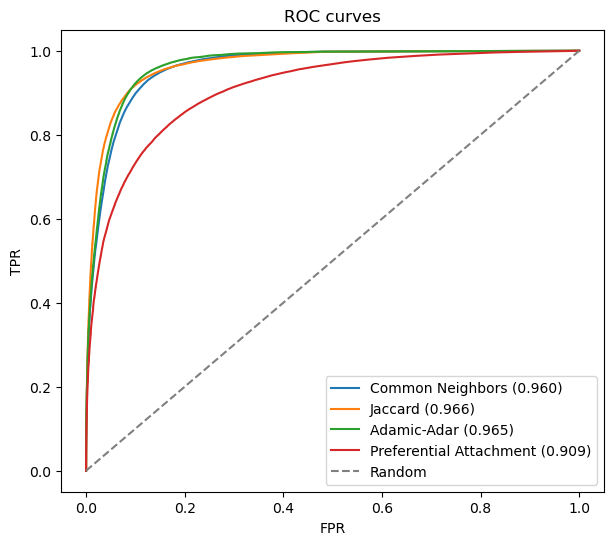

,predictor,AUROC
1,Jaccard,0.966487
2,Adamic-Adar,0.965206
0,Common Neighbors,0.960384
3,Preferential Attachment,0.908922


In [9]:
auc_rows = []
plt.figure(figsize=(7, 6))

for name, values in scores.items():
    fpr, tpr, thresholds = roc_curve(labels, values)
    auc_value = auc(fpr, tpr)

    auc_rows.append({
        "predictor": name,
        "AUROC": auc_value,
    })

    plt.plot(fpr, tpr, label=f"{name} ({auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.ylabel("TPR")
plt.xlabel("FPR")
plt.title("ROC curves")
plt.legend()
plt.show()

pd.DataFrame(auc_rows).sort_values("AUROC", ascending=False)


In [10]:
def precision_at_k(labels, values, k):
    order = np.argsort(values)[::-1][:k]
    return labels[order].mean()


k_values = [10, 50, 100, 500, 1000]
precision_rows = []

for name, values in scores.items():
    row = {"predictor": name}
    for k in k_values:
        row[f"P@{k}"] = precision_at_k(labels, values, k)
    precision_rows.append(row)

pd.DataFrame(precision_rows)


,predictor,P@10,P@50,P@100,P@500,P@1000
0,Common Neighbors,1.0,1.0,1.00,1.000,1.000
1,Jaccard,0.8,0.8,0.88,0.958,0.974
2,Adamic-Adar,1.0,1.0,1.00,1.000,1.000
3,Preferential Attachment,1.0,1.0,1.00,1.000,1.000


<a id='semantic'></a>
## Reading the highest ranked predictions

The metadata are used only to make the top predictions easier to discuss in the report.


In [11]:
metadata = pd.read_csv(METADATA_PATH)
metadata = metadata.set_index("ticker")


def get_metadata_value(ticker, column):
    if ticker in metadata.index:
        return metadata.loc[ticker, column]
    return "Unknown"


top_edges = predictions.sort_values("Adamic-Adar", ascending=False).head(20).copy()

top_edges["source_company"] = top_edges["source"].apply(lambda x: get_metadata_value(x, "company"))
top_edges["source_sector"] = top_edges["source"].apply(lambda x: get_metadata_value(x, "sector"))
top_edges["target_company"] = top_edges["target"].apply(lambda x: get_metadata_value(x, "company"))
top_edges["target_sector"] = top_edges["target"].apply(lambda x: get_metadata_value(x, "sector"))

top_edges[[
    "source", "target", "is_test_edge", "Adamic-Adar",
    "source_sector", "target_sector", "source_company", "target_company"
]]


,source,target,is_test_edge,Adamic-Adar,source_sector,target_sector,source_company,target_company
46457,QQQ,SPY,1,231.072474,NaN,NaN,Invesco QQQ Trust,State Street SPDR S&P 500 ETF Trust
74903,DIA,QQQ,1,181.561189,NaN,NaN,State Street SPDR Dow Jones Industrial Average...,Invesco QQQ Trust
58597,AAPL,NVDA,1,128.887595,Technology,Technology,Apple Inc.,NVIDIA Corporation
28069,NVDA,SPY,1,126.334647,Technology,NaN,NVIDIA Corporation,State Street SPDR S&P 500 ETF Trust
40583,AMD,NVDA,1,123.482001,Technology,Technology,"Advanced Micro Devices, Inc.",NVIDIA Corporation
83530,AAPL,TSLA,1,123.141315,Technology,Consumer Cyclical,Apple Inc.,"Tesla, Inc."
11467,MSFT,TSLA,1,104.879322,Technology,Consumer Cyclical,Microsoft Corporation,"Tesla, Inc."
63866,AAPL,GOOGL,1,104.212277,Technology,Communication Services,Apple Inc.,Alphabet Inc.
41654,AMZN,META,1,100.410249,Consumer Cyclical,Communication Services,"Amazon.com, Inc.","Meta Platforms, Inc."
83029,NKE,TSLA,1,93.505810,Consumer Cyclical,Consumer Cyclical,"NIKE, Inc.","Tesla, Inc."
